# TASK 1 – Iris Flower Classification

## Objective

Train a machine learning classification model to identify the species of an iris flower
(Setosa, Versicolor, or Virginica) based on its physical measurements.

## Tech Stack

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## Dataset

The Iris dataset is built into Scikit-learn, so no external download is required.

In [1]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Display plots inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the Iris dataset from scikit-learn

iris = load_iris()

print("Iris dataset loaded successfully!")

Iris dataset loaded successfully!


In [3]:
# Display basic information about the Iris dataset

print("Feature Names:")
print(iris.feature_names)

print("\nTarget Names:")
print(iris.target_names)

print("\nDataset Shape:")
print(iris.data.shape)

Feature Names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target Names:
['setosa' 'versicolor' 'virginica']

Dataset Shape:
(150, 4)


In [4]:
# Create a Pandas DataFrame

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target values
df["target"] = iris.target

# Add species names
df["species"] = df["target"].map({
    0: "setosa",
    1: "versicolor",
    2: "virginica"
})

# Display first 5 rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [5]:
# Check the number of rows and columns

print("Dataset Shape:", df.shape)

Dataset Shape: (150, 6)


In [6]:
# Check data types of all columns

print(df.dtypes)

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object


In [7]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64


In [8]:
# Display descriptive statistics

df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [9]:
# Count the number of samples for each species

print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## EDA Summary

- The Iris dataset contains 150 observations and 6 columns.
- There are 4 numerical flower measurement features.
- The dataset contains 3 flower species: Setosa, Versicolor, and Virginica.
- There are no missing/null values.
- The numerical features are stored as float values.
- The target column contains the encoded species classes.
- Each species has 50 observations, making the dataset balanced.

# Data Visualization

Visualizations help us understand the distribution of the features and identify differences between the three Iris species.

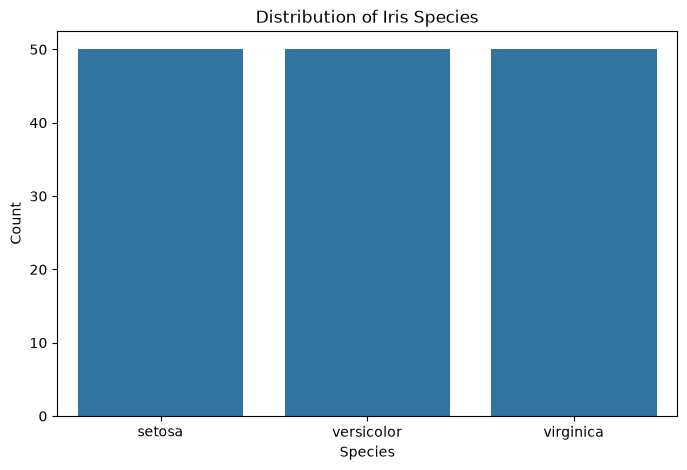

In [10]:
# Visualize the number of samples for each species

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")

plt.show()

## Pairplot

A pairplot shows the relationship between every pair of numerical features.
Different colors represent different Iris species.

This helps us visually identify which features are most useful for classification.

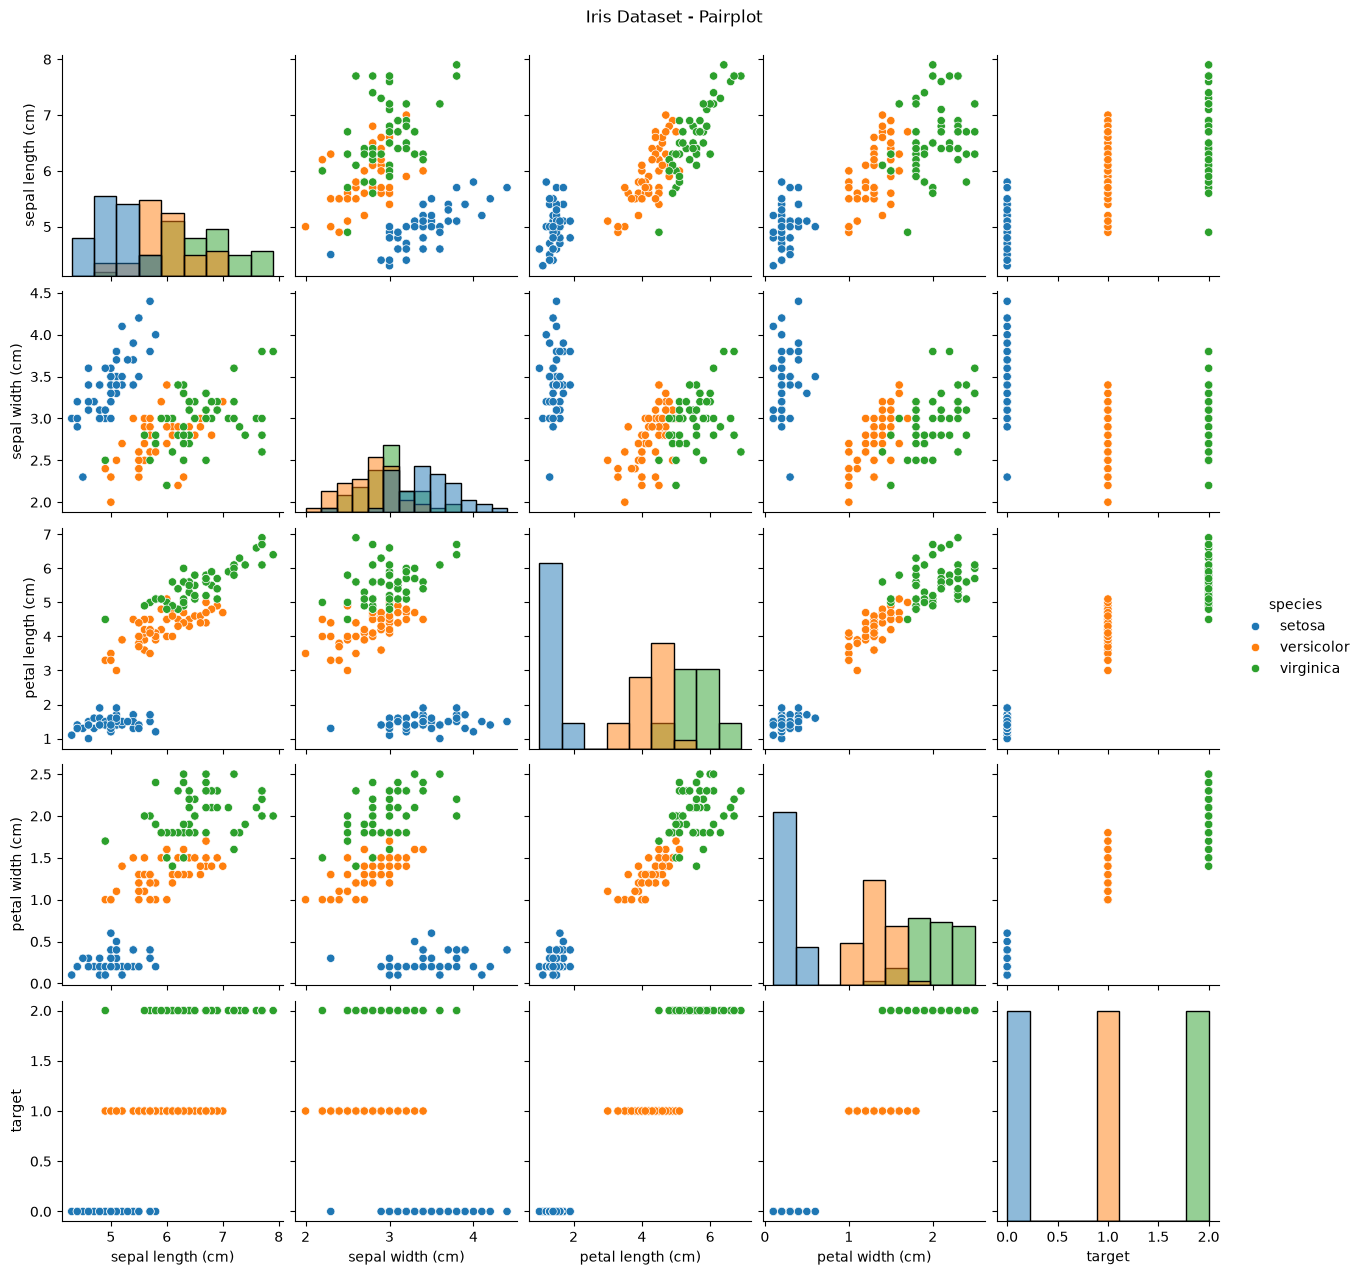

In [11]:
# Create a pairplot to visualize relationships between features

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Iris Dataset - Pairplot", y=1.02)

plt.show()

## Box Plots

Box plots help us compare the distribution, median, spread, and potential outliers
of each feature across the three Iris species.

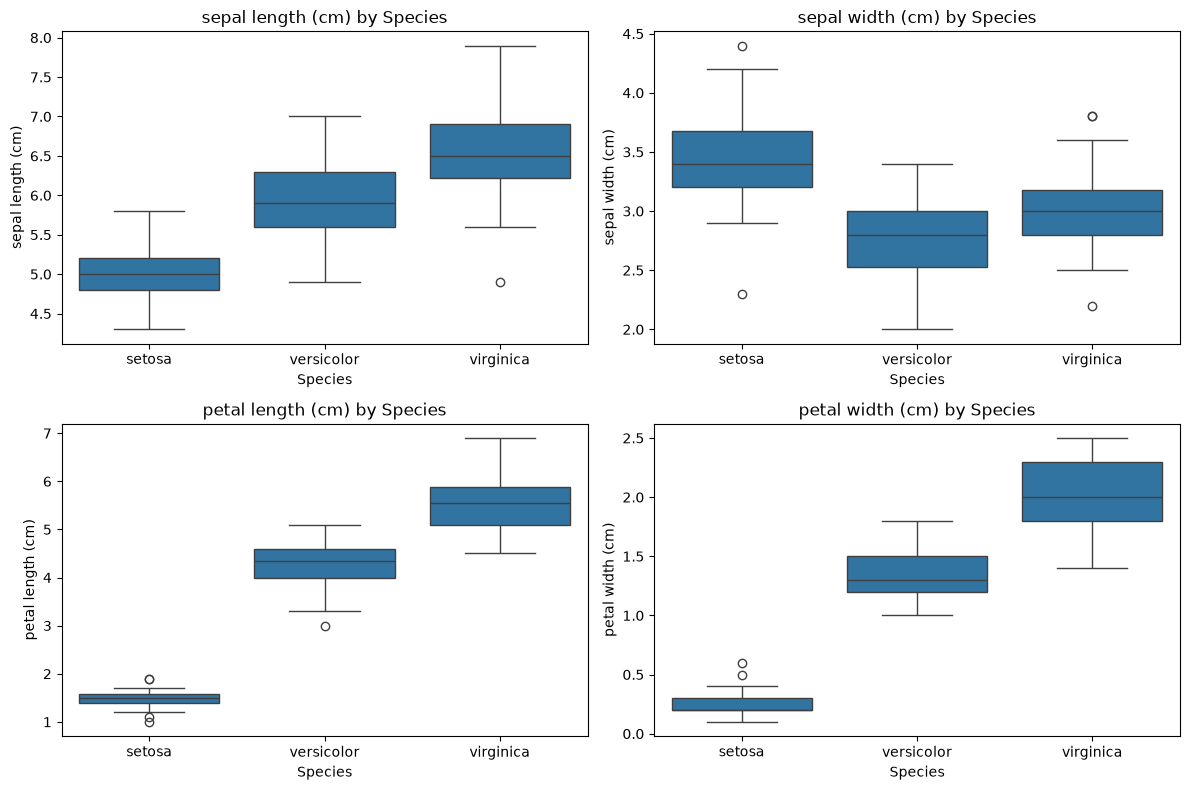

In [12]:
# Create box plots for all numerical features

features = iris.feature_names

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)
    
    sns.boxplot(
        data=df,
        x="species",
        y=feature
    )
    
    plt.title(f"{feature} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

## Feature Selection Discussion

Based on the pairplot and box plots:

- Petal length and petal width appear to be the most discriminative features.
- These two features show clear differences between the three species.
- Setosa is especially easy to distinguish using petal measurements.
- Sepal length and sepal width also provide useful information, but there is more overlap between Versicolor and Virginica.
- Therefore, petal length and petal width appear to be the strongest features for Iris species classification.

For the machine learning models, all four features will initially be used so that the models can learn from the complete dataset.

# Machine Learning Model Preparation

Before training the models, we need to separate the input features (X) from the target variable (y).

In [13]:
# Select input features

X = df[iris.feature_names]

# Select target variable
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (150, 4)
Target shape: (150,)


# Train-Test Split

The dataset is divided into training and testing sets.

- 80% of the data will be used to train the machine learning models.
- 20% will be used to evaluate the models on unseen data.

In [14]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


# Model 1 – Logistic Regression

Logistic Regression is a classification algorithm used to predict the class of an observation.

We will train the model using the training data and then evaluate it on the test data.

In [15]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(max_iter=200)

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [16]:
# Import evaluation metrics

from sklearn.metrics import accuracy_score

# Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 96.67 %


In [17]:
# Display classification report

from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=iris.target_names
    )
)

Logistic Regression Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



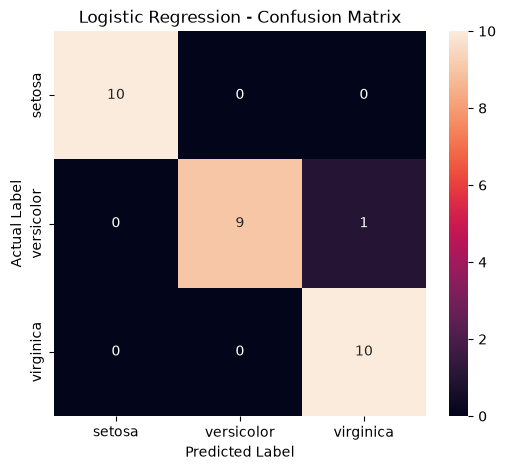

In [18]:
# Create confusion matrix

from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# Model 2 – K-Nearest Neighbours (KNN)

K-Nearest Neighbours classifies a data point based on the classes of its nearest observations.

We will train a KNN classifier and compare its performance with Logistic Regression.

In [19]:
# Import KNN

from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test)

print("KNN model trained successfully!")

KNN model trained successfully!


In [20]:
# Calculate KNN accuracy

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:",
      round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 100.0 %


In [21]:
# Display KNN classification report

print("KNN Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=iris.target_names
    )
)

KNN Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



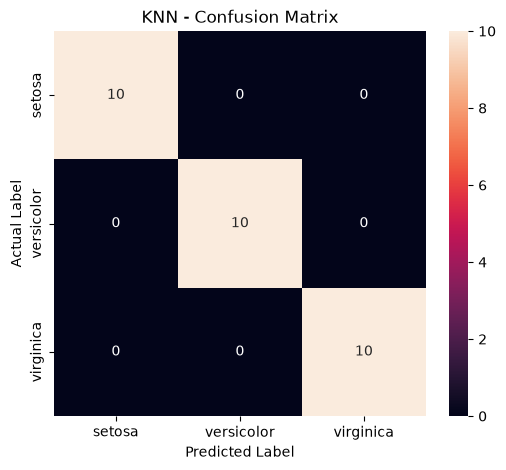

In [22]:
# Create KNN confusion matrix

cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# Model Comparison

We trained two different classification algorithms:

1. Logistic Regression
2. K-Nearest Neighbours (KNN)

We will now compare their accuracy scores and identify the better-performing model.

In [23]:
# Compare model accuracy

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbours"
    ],
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

results

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.966667,96.666667
1,K-Nearest Neighbours,1.000000,100.000000


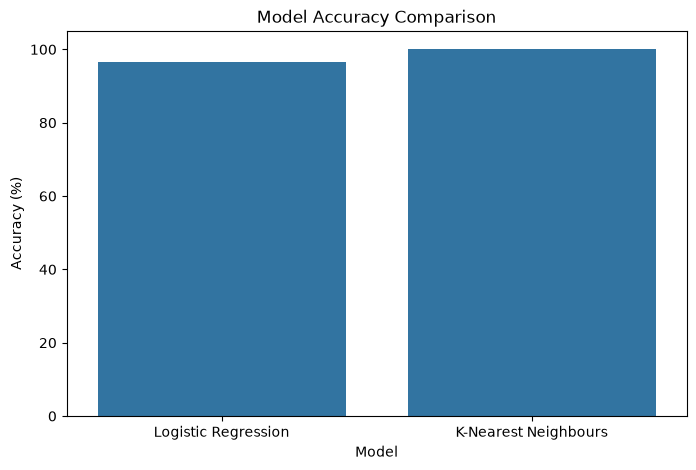

In [24]:
# Visualize model accuracy

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

plt.show()

# Model 3 – Random Forest

Random Forest is an ensemble machine learning algorithm that combines multiple
Decision Trees to make predictions.

It is useful for classification because it can capture complex relationships
between features and target classes.

In [25]:
# Import Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [26]:
# Calculate Random Forest accuracy

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(
    "Random Forest Accuracy:",
    round(rf_accuracy * 100, 2),
    "%"
)

Random Forest Accuracy: 90.0 %


In [27]:
# Display Random Forest classification report

print("Random Forest Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=iris.target_names
    )
)

Random Forest Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



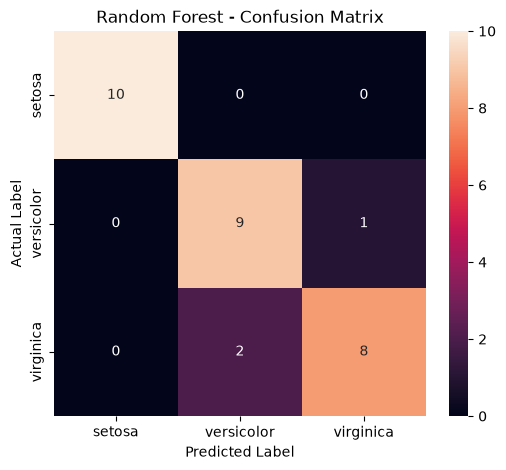

In [28]:
# Create Random Forest confusion matrix

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# Final Model Comparison

Three classification algorithms were trained and evaluated:

1. Logistic Regression
2. K-Nearest Neighbours
3. Random Forest

Their accuracy scores will now be compared to determine the best-performing model.

In [29]:
# Compare all three models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbours",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy,
        rf_accuracy
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

results.sort_values(
    by="Accuracy (%)",
    ascending=False
)

,Model,Accuracy,Accuracy (%)
1,K-Nearest Neighbours,1.000000,100.000000
0,Logistic Regression,0.966667,96.666667
2,Random Forest,0.900000,90.000000


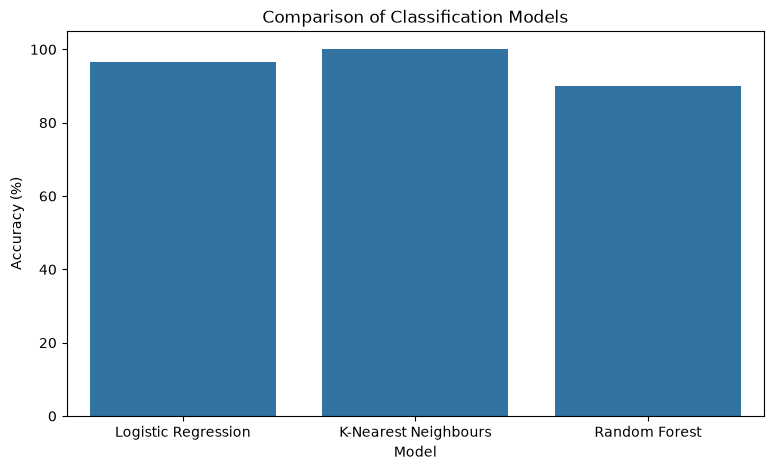

In [30]:
# Plot accuracy comparison

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy (%)"
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

plt.show()

In [31]:
# Identify the best-performing model

best_model_row = results.loc[
    results["Accuracy"].idxmax()
]

best_model_name = best_model_row["Model"]
best_accuracy = best_model_row["Accuracy (%)"]

print("Best Performing Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy, 2), "%")

Best Performing Model: K-Nearest Neighbours
Best Accuracy: 100.0 %


# Feature Importance

Random Forest provides feature importance scores that help us understand
which physical measurements are most useful for predicting the Iris species.

In [32]:
# Calculate Random Forest feature importance

feature_importance = pd.DataFrame({
    "Feature": iris.feature_names,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
3,petal width (cm),0.437185
2,petal length (cm),0.431466
0,sepal length (cm),0.116349
1,sepal width (cm),0.015000


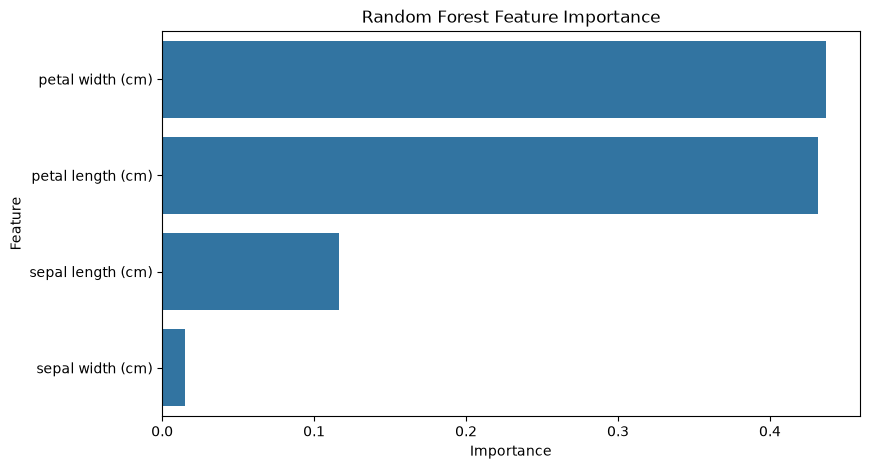

In [33]:
# Visualize feature importance

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()